In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/twitter-airline-sentiment/Tweets.csv
/kaggle/input/twitter-airline-sentiment/database.sqlite


## 1. Introduction

This technical report applies sentiment analysis to a dataset of tweets directed at major US airlines. The goal is to compare multiple sentiment modeling approaches and evaluate performance using standard classification metrics such as accuracy and F1-score. The analysis also examines how sentiment is distributed across the dataset and how it varies by airline.

Airline-related tweets are well suited for sentiment analysis because they contain emotionally charged language and frequent complaints, things that are frequent across social media. This dataset is well suited for this assignment because it contains short, informal social media text with human-annotated sentiment labels, making it ideal for evaluating different modeling approaches.

## Report Structure

1. Introduction  
2. Data Loading and Initial Inspection  
3. Data Preparation  
4. Text Preprocessing  
5. Exploratory Analysis  
6. Train/Test Split  
7. TF-IDF + Logistic Regression  
8. TF-IDF + Linear Support Vector Machine  
9. Lexicon-Based Baseline (VADER)  
10. TF-IDF + Multinomial Naive Bayes  
11. Model Comparison  
12. Sentiment Trends Across the Dataset  
13. Methodological Considerations and Limitations  
14. Conclusion

In [2]:
df = pd.read_csv("/kaggle/input/twitter-airline-sentiment/Tweets.csv")

print("Shape:", df.shape)
df.head()

Shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


### 2. Data Loading and Initial Inspection

I start by loading the dataset and checking the number of observations and columns. I also preview a few rows to get an idea of what the data looks like. 


In [3]:
df = df[["text", "airline_sentiment", "airline", "tweet_created"]].copy()
df = df.rename(columns={"airline_sentiment": "sentiment"})

df["sentiment"].value_counts()

sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

## 3. Data Preparation

For this analysis, I keep only the columns needed for modeling and interpretation:
- `text` (tweet content)
- `sentiment` ("ground-truth" label: negative / neutral / positive)
- `airline` (for subgroup analysis)
- `tweet_created` (for trend plots if I can)

Also, the label distribution shows a clear class imbalance, with negative sentiment making up the majority of observations.

In [4]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+", "", text)   
    text = re.sub(r"@\w+", "", text)      
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text", "sentiment"]].head()

,text,clean_text,sentiment
0,@VirginAmerica What @dhepburn said.,what said.,neutral
1,@VirginAmerica plus you've added commercials t...,plus you've added commercials to the experienc...,positive
2,@VirginAmerica I didn't today... Must mean I n...,i didn't today... must mean i need to take ano...,neutral
3,@VirginAmerica it's really aggressive to blast...,"it's really aggressive to blast obnoxious ""ent...",negative
4,@VirginAmerica and it's a really big bad thing...,and it's a really big bad thing about it,negative


## 4. Text Preprocessing

Before I fit any models, I do some light cleaning on the text data to reduce noise while keeping sentiment-relevant information:
- convert text to lowercase
- remove URLs and @mentions
- normalize whitespace for consistency

I tried to keep things like punctuation and emojis as they can carry sentiment signals, especially in text on social media.

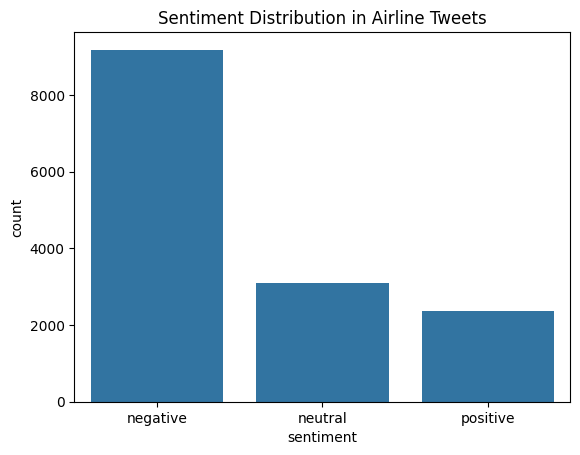

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot 1
sns.countplot(
    data=df,
    x="sentiment",
    order=["negative", "neutral", "positive"]
)
plt.title("Sentiment Distribution in Airline Tweets")
plt.show()

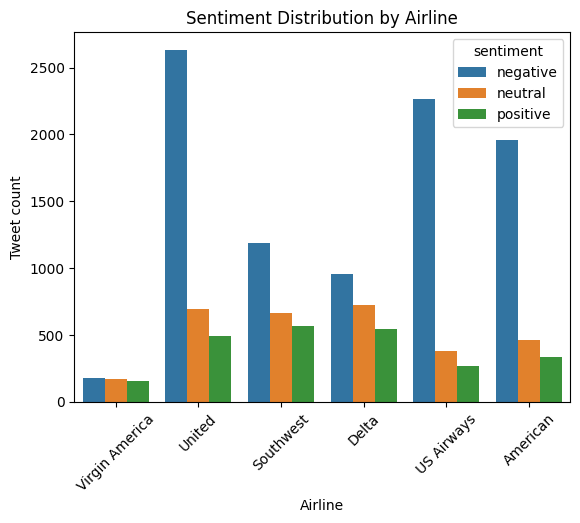

In [6]:
# Plot 2
sns.countplot(
    data=df,
    x="airline",
    hue="sentiment",
    hue_order=["negative", "neutral", "positive"]
)
plt.title("Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Tweet count")
plt.xticks(rotation=45)
plt.show()

## 5. Exploratory Analysis

I first examine the distribution of sentiment labels in the dataset. This is important because class imbalance can affect model performance and can make accuracy misleading if one class dominates. I use a simple count plot to visualize label frequencies (plot 1), and I confirm what I saw earlier in the data, there are far more negative sentiment tweets that either neutral or positive.

To further contextualize sentiment patterns, I examine how sentiment is distributed across airlines with plot 2. While negative sentiment dominates for all carriers, the relative proportions of neutral and positive tweets vary by airline. This suggests differences in customer experience and public perception across airlines and helps explain why negative sentiment is consistently easier for models to identify than neutral or positive sentiment.

In [7]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape[0])
print("Test size:", X_test.shape[0])

Train size: 11712
Test size: 2928


## 6. Train/Test Split

To evaluate models fairly, I split the data into training and test sets using a stratified split. I did this to make sure that the sentiment classes appear in roughly the same proportions in both sets. All models are evaluated on the same test set for consistency.

Logistic Regression Accuracy: 0.7650273224043715

Classification Report:
               precision    recall  f1-score   support

    negative       0.79      0.94      0.85      1835
     neutral       0.63      0.42      0.50       620
    positive       0.81      0.55      0.65       473

    accuracy                           0.77      2928
   macro avg       0.74      0.64      0.67      2928
weighted avg       0.76      0.77      0.75      2928



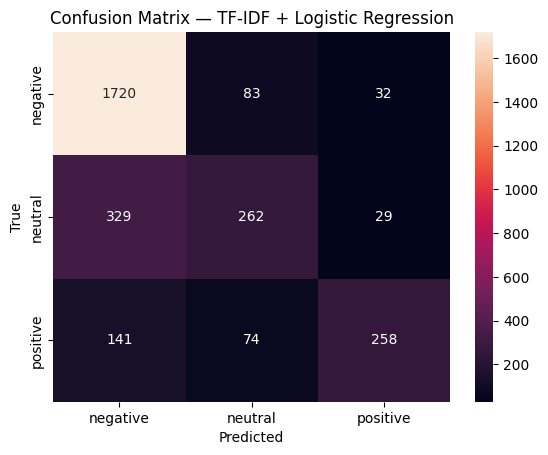

In [8]:
# 7. Model 1 -TF-IDF + Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1) Define model (keep params identical)
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("clf", LogisticRegression(
        max_iter=1000
    ))
])

# 2) Fit
lr_model.fit(X_train, y_train)

# 3) Predict
y_pred_lr = lr_model.predict(X_test)

# 4) Evaluate 
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# 5) Confusion matrix 
cm = confusion_matrix(y_test, y_pred_lr, labels=["negative", "neutral", "positive"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"]
)
plt.title("Confusion Matrix — TF-IDF + Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Model 1 uses TF-IDF features with logistic regression to predict tweet sentiment. TF-IDF turns the tweet text into numeric features by giving more weight to words that are informative across the dataset.

On the test set, the model reaches about 0.76 accuracy. It performs best on negative tweets (high recall), while neutral is the hardest class, with many neutral tweets being predicted as negative. The confusion matrix confirms that most mistakes happen around the neutral class, which tends to overlap with both positive and negative language. This can be seen visualy where a large number of neutral tweets are misclassified as negative (329). By comparison, confusion between negative and positive sentiment is much less, with very low counts. This means there is clearer separation for strongly polarized language.

Linear SVM Accuracy: 0.7681010928961749

Classification Report:
               precision    recall  f1-score   support

    negative       0.83      0.89      0.86      1835
     neutral       0.58      0.53      0.55       620
    positive       0.75      0.61      0.67       473

    accuracy                           0.77      2928
   macro avg       0.72      0.68      0.69      2928
weighted avg       0.76      0.77      0.76      2928



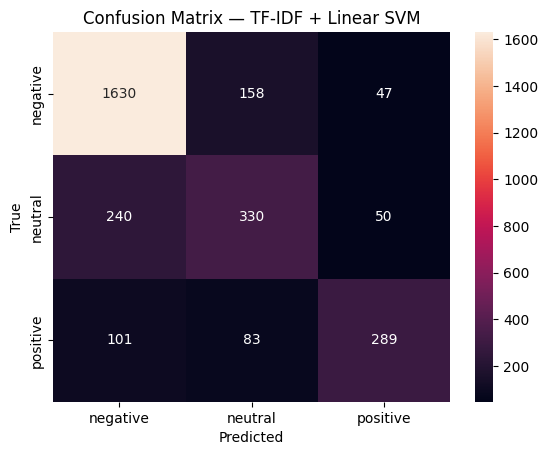

In [9]:
# 8. Model 2 - TF-IDF + Linear Support Vector Machine

from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1) Define model 
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("clf", LinearSVC())
])

# 2) Fit
svm_model.fit(X_train, y_train)

# 3) Predict
y_pred_svm = svm_model.predict(X_test)

# 4) Evaluate 
print("Linear SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_svm))

# 5) Confusion matrix 
cm = confusion_matrix(y_test, y_pred_svm, labels=["negative", "neutral", "positive"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"]
)
plt.title("Confusion Matrix — TF-IDF + Linear SVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


Model 2 uses a linear Support Vector Machine (SVM) with the same TF-IDF features as the logistic regression model. Linear SVMs are well suited for high-dimensional text data such as this.

This model achieves a slightly higher accuracy (~0.77) than logistic regression and shows improved performance for neutral sentiment, which still remains the most difficult class overall. Negative sentiment continues to be identified most reliably, reflecting both clearer linguistic cues and the class imbalance in the data i talked about earlier.

The confusion matrix shows fewer neutral-to-negative errors than in the logistic regression model, visible in the lighter shading and lower count for neutral tweets misclassified as negative (240) compared to Model 1. Correctly classified neutral tweets increase to 330, shown by the darker diagonal cell. Confusion between negative and positive sentiment remains rare, indicating that strongly polarized language is well separated by the SVM.

VADER Accuracy: 0.5430327868852459

Classification Report:
               precision    recall  f1-score   support

    negative       0.89      0.49      0.63      1835
     neutral       0.40      0.46      0.43       620
    positive       0.34      0.87      0.49       473

    accuracy                           0.54      2928
   macro avg       0.54      0.61      0.52      2928
weighted avg       0.70      0.54      0.56      2928



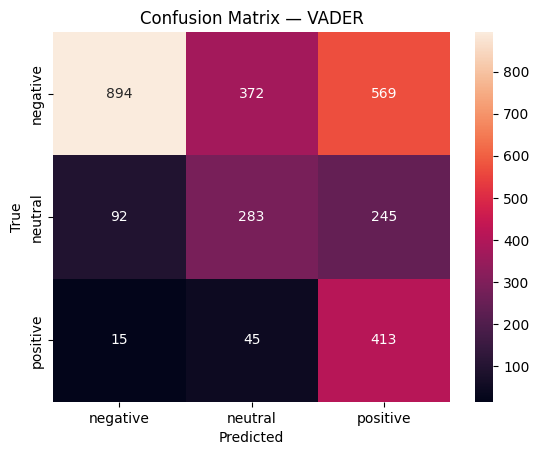

In [10]:
# 9. Model 3 - VADER

from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1) Initialize VADER
vader = SentimentIntensityAnalyzer()

# 2) Sentiment mapping function
def vader_sentiment(text):
    score = vader.polarity_scores(text)["compound"]
    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"

# 3) Predict on test set without fitting
y_pred_vader = X_test.apply(vader_sentiment)

# 4) Evaluate
print("VADER Accuracy:", accuracy_score(y_test, y_pred_vader))
print("\nClassification Report:\n", classification_report(y_test, y_pred_vader))

# 5) Confusion matrix
cm = confusion_matrix(y_test, y_pred_vader, labels=["negative", "neutral", "positive"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"]
)
plt.title("Confusion Matrix — VADER")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

Model 3 uses VADER, a rule-based sentiment analyzer designed for social media text. Unlike the previous models, VADER does not learn from the data and instead assigns sentiment based on predefined word scores and intensity rules.

VADER performs substantially worse than the supervised models, with an accuracy of about 0.54. While it captures strongly positive and negative language pretty well, it struggles to identify neutral sentiment, leading to frequent misclassifications. This makes VADER a useful baseline like model 1 but not good enough for the multi-class nature of this dataset.

The confusion matrix deos a good job of highlightinh VADER’s limitations clearly. A large number of negative tweets are misclassified as positive (569 cases), shown by the cell in the top-right of the matrix. Neutral tweets are also frequently misclassified as either negative (92 cases) or positive (245 cases). In contrast, correctly classified neutral tweets are fewer (283 cases), explaining the model’s weak performance on neutral sentiment.

Naive Bayes Accuracy: 0.7237021857923497

Classification Report:
               precision    recall  f1-score   support

    negative       0.71      0.99      0.83      1835
     neutral       0.75      0.24      0.37       620
    positive       0.85      0.33      0.48       473

    accuracy                           0.72      2928
   macro avg       0.77      0.52      0.56      2928
weighted avg       0.74      0.72      0.67      2928



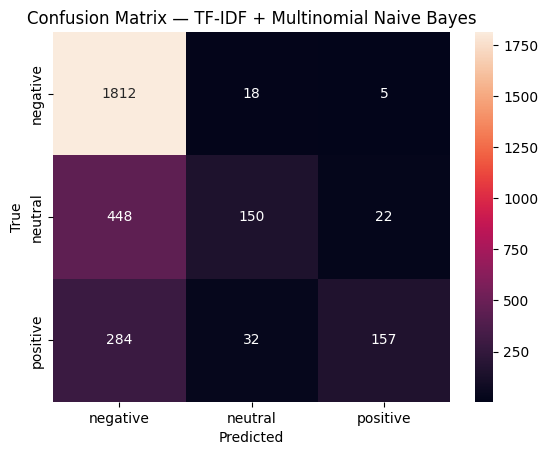

In [11]:
# 10. Model 4 - TF-IDF + Multinomial Naive Bayes

from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline as SklearnPipeline

# 1) Define model 
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000
    )),
    ("clf", MultinomialNB())
])

# 2) Fit
nb_model.fit(X_train, y_train)

# 3) Predict
y_pred_nb = nb_model.predict(X_test)

# 4) Evaluate
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_nb))

# 5) Confusion matrix
cm = confusion_matrix(y_test, y_pred_nb, labels=["negative", "neutral", "positive"])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["negative", "neutral", "positive"],
    yticklabels=["negative", "neutral", "positive"]
)
plt.title("Confusion Matrix — TF-IDF + Multinomial Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

For model 4 I decided to go with Multinomial Naive Bayes with the same TF-IDF features as the previous models. This approach is a classic text-classification baseline in other similar studies that often performs well on sparse word-based features, which are present in this data, but it can be sensitive to class imbalance, which is also present in this data.

On the test set, the model reaches about 0.72 accuracy, but its performance is uneven across classes. It identifies negative sentiment extremely well, while neutral and positive tweets are frequently pulled into the negative class. This makes it a useful contrast model, even though it is not the best overall performer.

The confusion matrix shows this bias clearly. The predicted “negative” column includes 448 neutral tweets predicted as negative and 284 positive tweets predicted as negative. Meanwhile, the diagonal cell for correctly predicted neutral tweets is relatively small (150). In other words, Naive Bayes achieves decent accuracy largely by strongly favoring the dominant negative class.

### 11. Model Comparison

To compare models, I focus on accuracy and F1-scores, since the dataset is imbalanced and overall accuracy alone can be misleading. Looking across models highlights not only which approach performs best, but also how different methods handle ambiguous sentiment.

Among the supervised learning models, the linear SVM performs the best overall, achieving the highest accuracy and more balanced F1-scores across sentiment classes. Logistic regression performs similarly but struggles more with neutral sentiment, which lowers its macro F1-score. Multinomial Naive Bayes reaches reasonable accuracy but shows a strong tendency to predict the dominant negative class, leading to weak performance on neutral and positive tweets.

The VADER baseline performs substantially worse than all supervised models. While it often captures strongly positive or negative language, it fails to reliably identify neutral sentiment, resulting in low overall accuracy and uneven F1-scores. 

This comparison shows that supervised machine learning methods clearly outperform rule-based approaches for this task, with the linear SVM providing the best balance between accuracy and class-level performance.

## 12. Sentiment Trends Across the Dataset

Building on the earlier exploratory analysis, I want to briefly and explicity talk about thedataset-level sentiment patterns across airlines. 

Although negative sentiment dominates for all carriers, the mix of neutral and positive tweets varies noticeably across airlines. These differences likely reflect variation in customer experience and public perception. This pattern also helps explain results from the modeling sections, since negative sentiment is so prevalent across airlines, all models tend to identify negative tweets more reliably than neutral or positive ones.


### 13. Methodological Considerations and Limitations

I wanted to talk about a few considerations a limitation that I wanted to outline before the end of this report. 

Firstly, the dataset is highly imbalanced, with negative sentiment appearing far more often than neutral or positive sentiment. This imbalance affects how the models behave and helps explain why all approaches show higher recall for negative tweets while struggling more with neutral ones.

Neutral sentiment is also inherently difficult to classify in short social media posts. Many neutral tweets contain mixed or ambiguous language, making them easy to confuse with weakly positive or weakly negative sentiment. This pattern appears consistently across models, only supporting the difficult nature of classifying neutral sentiment on social media.

I made the choice to include a confussion matrix with every model to better understand the errors iof each model and have a standard to compare all of them visually. While accuracy and F1-scores summarize overall performance, the confusion matrices reveal where mistakes occur, such as how Naive Bayes tends to over-predict negative sentiment or the broader difficulty all models have in separating neutral tweets.

Finally, this analysis relies on the sentiment labels provided with the dataset and does not use domain-specific tuning or external context. As a result, the models capture general sentiment patterns but may miss nuances such as sarcasm or airline-specific events, which are common in social media conversations, and cannot be identifies accuratly without being classified by hand.

### 14. Conclusion

This project compared several sentiment analysis approaches on airline-related tweets, including a lexicon-based baseline and multiple supervised machine learning models. The results show that supervised models clearly outperform rule-based methods such as VADER, with the linear SVM providing the best overall balance of accuracy and class-level performance.

The analysis also highlights key challenges of sentiment classification in social media data. Class imbalance and ambiguous neutral language consistently affected model performance, which helps explain why negative sentiment was easier to identify across all approaches. Dataset-level visualizations further supported these findings by showing that negative sentiment dominates airline-related discussions, with variation across carriers.

This project demonstrates the effectiveness of supervised machine learning for sentiment analysis while emphasizing the need for careful evaluation beyond accuracy alone. Future work could explore domain-specific tuning or alternative text representations to further improve model performance and interpretation.